In [33]:
import numpy as np
import torch
from training import AllenCahnDataset, train_model
from model import AllenCahnFNO
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import random


In [34]:
# freeze random seed for reproducibility
seed = 0
random.seed(seed)
np.random.seed(seed)
torch.random.manual_seed(seed)
torch.manual_seed(seed)

### Load Dataset

In [35]:
# load data
time_points = np.array([0, 0.25, 0.5, 0.75, 1.0])

train_idx = np.random.choice(1000, 900, replace=False)
val_idx = np.setdiff1d(np.arange(1000), train_idx)

train_data = np.load('../Foundational_Models_for_Allen_Cahn/dataset/train/train_data.npz', allow_pickle=True)
train_data = dict(train_data)
train_epsilon = [0.02, 0.01, 0.005]
new_train_data = {}
val_data = {}
for key in train_data.keys():
    new_train_data[float(key)] = train_data[key][train_idx]
    val_data[float(key)] = train_data[key][val_idx]
print(train_data.keys())

test_data = np.load('../Foundational_Models_for_Allen_Cahn/dataset/test/test_data.npz', allow_pickle=True)
test_data = dict(test_data)
test_epsilon = [0.02, 0.015, 0.01, 0.0075, 0.005]
new_test_data = {}
for key in test_data.keys():
    new_test_data[float(key)] = test_data[key]

ood_data = np.load('../Foundational_Models_for_Allen_Cahn/dataset/ood/ood_data.npz', allow_pickle=True)
ood_data = dict(ood_data)
ood_epsilon = [0.05, 0.03, 0.025, 0.003, 0.002, 0.001]
new_ood_data = {}
for key in ood_data.keys():
    new_ood_data[float(key)] = ood_data[key]

high_freq_data = np.load('../Foundational_Models_for_Allen_Cahn/dataset/high_freq/high_freq_data.npz', allow_pickle=True)
high_freq_data = dict(high_freq_data)
high_freq_epsilon = [0.02, 0.01, 0.005]
new_high_freq_data = {}
for key in high_freq_data.keys():
    new_high_freq_data[float(key)] = high_freq_data[key]

Train_Dataset = AllenCahnDataset(new_train_data, train_epsilon, time_points)
Val_Dataset = AllenCahnDataset(val_data, train_epsilon, time_points)
Test_Dataset = AllenCahnDataset(new_test_data, test_epsilon, time_points)
OOD_Dataset = AllenCahnDataset(new_ood_data, ood_epsilon, time_points)
High_Freq_Dataset = AllenCahnDataset(new_high_freq_data, high_freq_epsilon, time_points)


dict_keys(['0.02', '0.01', '0.005'])


### Construct the Model and Start Training

In [36]:
model = AllenCahnFNO()
model, training_losses, validation_losses = train_model(model, new_train_data, val_data, train_epsilon, time_points, batch_size=32, epochs=150, device='cpu',
                learning_rate=1e-3, curriculum_steps=None)

Epoch 0: train_loss=0.085727, val_loss=0.054098
Epoch 1: train_loss=0.052780, val_loss=0.053765
Epoch 2: train_loss=0.052311, val_loss=0.054262
Epoch 3: train_loss=0.051536, val_loss=0.051517
Epoch 4: train_loss=0.050606, val_loss=0.049921
Epoch 5: train_loss=0.049436, val_loss=0.050704
Epoch 6: train_loss=0.048168, val_loss=0.050910
Epoch 7: train_loss=0.046406, val_loss=0.048627
Epoch 8: train_loss=0.045287, val_loss=0.045316
Epoch 9: train_loss=0.043620, val_loss=0.042669
Epoch 10: train_loss=0.041334, val_loss=0.040148
Epoch 11: train_loss=0.039207, val_loss=0.038072
Epoch 12: train_loss=0.035437, val_loss=0.037988
Epoch 13: train_loss=0.032904, val_loss=0.030388
Epoch 14: train_loss=0.027893, val_loss=0.027602
Epoch 15: train_loss=0.024319, val_loss=0.022168
Epoch 16: train_loss=0.022091, val_loss=0.021202
Epoch 17: train_loss=0.019550, val_loss=0.017569
Epoch 18: train_loss=0.017174, val_loss=0.016190
Epoch 19: train_loss=0.016141, val_loss=0.016574
Epoch 20: train_loss=0.015356,

### Visualize Training and Evaluation Loss

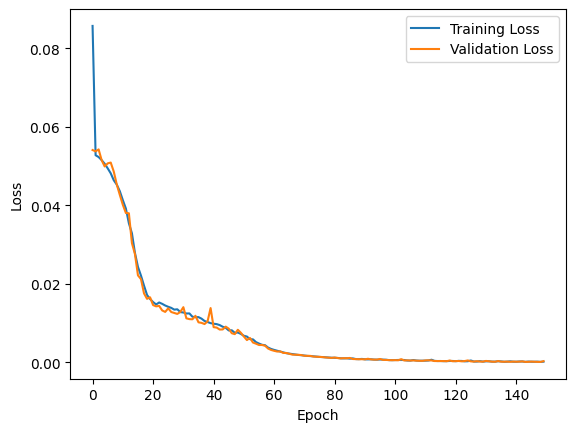

In [37]:
# visualize training and validation losses
plt.figure()
plt.plot(training_losses, label='Training Loss')
plt.plot(validation_losses, label='Validation Loss')
plt.legend()
# plt.yscale('log')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

### Model Testing

In [38]:
device = torch.device('cpu')
model = AllenCahnFNO()
model.load_state_dict(torch.load('../Foundational_Models_for_Allen_Cahn/best_model.pt'))
model.eval()

val_loader = DataLoader(Val_Dataset, batch_size=32, shuffle=False)
val_loss = 0
relative_l2_error_val = 0

relative_l2_error_val_list = {}
n_val_list = {}
for epsilon in train_epsilon:
    relative_l2_error_val_list[epsilon] = 0
    n_val_list[epsilon] = 0

with torch.no_grad():
    for batch in val_loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        pred = model(batch['initial'], batch['epsilon'], batch['times'])
        val_loss += nn.MSELoss()(pred, batch['target']).item()
        loss_f = (torch.mean((batch['target'] - pred) ** 2, dim=-1) / torch.mean(batch['target'] ** 2, dim=-1)) ** 0.5 * 100
        relative_l2_error_val += loss_f.mean().item()
        for epsilon in train_epsilon:
            idx = batch['epsilon'] == epsilon
            if idx.sum() > 0:
                relative_l2_error_val_list[epsilon] += loss_f[idx.squeeze()].sum().item()
                n_val_list[epsilon] += idx.sum().item() * 4
val_loss /= len(val_loader)
relative_l2_error_val /= len(val_loader)
for epsilon in train_epsilon:
    relative_l2_error_val_list[epsilon] /= n_val_list[epsilon]

print(f'Validation Loss: {val_loss}')
print(f'Relative L2 Error: {relative_l2_error_val}')
print(f'Relative L2 Error for each epsilon: {relative_l2_error_val_list}')

test_loader = DataLoader(Test_Dataset, batch_size=32, shuffle=False)
test_loss = 0
relative_l2_error_test = 0

relative_l2_error_test_list = {}
n_test_list = {}
for epsilon in test_epsilon:
    relative_l2_error_test_list[epsilon] = 0
    n_test_list[epsilon] = 0
    
with torch.no_grad():
    for batch in test_loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        pred = model(batch['initial'], batch['epsilon'], batch['times'])
        test_loss += nn.MSELoss()(pred, batch['target']).item()
        loss_f = (torch.mean((batch['target'] - pred) ** 2, dim=-1) / torch.mean(batch['target'] ** 2, dim=-1)) ** 0.5 * 100
        relative_l2_error_test += loss_f.mean().item()
        for epsilon in test_epsilon:
            idx = batch['epsilon'] == epsilon
            if idx.sum() > 0:
                relative_l2_error_test_list[epsilon] += loss_f[idx.squeeze()].sum().item()
                n_test_list[epsilon] += idx.sum().item() * 4
test_loss /= len(test_loader)
relative_l2_error_test /= len(test_loader)
for epsilon in test_epsilon:
    relative_l2_error_test_list[epsilon] /= n_test_list[epsilon]

print(f'Testing Loss: {test_loss}')
print(f'Relative L2 Error: {relative_l2_error_test}')
print(f'Relative L2 Error for each epsilon: {relative_l2_error_test_list}')

ood_dataloader = DataLoader(OOD_Dataset, batch_size=32, shuffle=False)
ood_loss = 0
relative_l2_error_ood = 0

relative_l2_error_ood_list = {}
n_ood_list = {}
for epsilon in ood_epsilon:
    relative_l2_error_ood_list[epsilon] = 0
    n_ood_list[epsilon] = 0

with torch.no_grad():
    for batch in ood_dataloader:
        batch = {k: v.to(device) for k, v in batch.items()}
        pred = model(batch['initial'], batch['epsilon'], batch['times'])
        ood_loss += nn.MSELoss()(pred, batch['target']).item()
        loss_f = (torch.mean((batch['target'] - pred) ** 2, dim=-1) / torch.mean(batch['target'] ** 2, dim=-1)) ** 0.5 * 100
        relative_l2_error_ood += loss_f.mean().item()
        for epsilon in ood_epsilon:
            idx = batch['epsilon'] == epsilon
            if idx.sum() > 0:
                relative_l2_error_ood_list[epsilon] += loss_f[idx.squeeze()].sum().item()
                n_ood_list[epsilon] += idx.sum().item() * 4
ood_loss /= len(ood_dataloader)
relative_l2_error_ood /= len(ood_dataloader)
for epsilon in ood_epsilon:
    relative_l2_error_ood_list[epsilon] /= n_ood_list[epsilon]

print(f'OOD Loss: {ood_loss}')
print(f'Relative L2 Error: {relative_l2_error_ood}')
print(f'Relative L2 Error for each epsilon: {relative_l2_error_ood_list}')

high_freq_dataloader = DataLoader(High_Freq_Dataset, batch_size=32, shuffle=False)
high_freq_loss = 0
relative_l2_error_high_freq = 0

relative_l2_error_high_freq_list = {}
n_high_freq_list = {}
for epsilon in high_freq_epsilon:
    relative_l2_error_high_freq_list[epsilon] = 0
    n_high_freq_list[epsilon] = 0

with torch.no_grad():
    for batch in high_freq_dataloader:
        batch = {k: v.to(device) for k, v in batch.items()}
        pred = model(batch['initial'], batch['epsilon'], batch['times'])
        high_freq_loss += nn.MSELoss()(pred, batch['target']).item()
        loss_f = (torch.mean((batch['target'] - pred) ** 2, dim=-1) / torch.mean(batch['target'] ** 2, dim=-1)) ** 0.5 * 100
        relative_l2_error_high_freq += loss_f.mean().item()
        for epsilon in high_freq_epsilon:
            idx = batch['epsilon'] == epsilon
            if idx.sum() > 0:
                relative_l2_error_high_freq_list[epsilon] += loss_f[idx.squeeze()].sum().item()
                n_high_freq_list[epsilon] += idx.sum().item() * 4
high_freq_loss /= len(high_freq_dataloader)
relative_l2_error_high_freq /= len(high_freq_dataloader)
for epsilon in high_freq_epsilon:
    relative_l2_error_high_freq_list[epsilon] /= n_high_freq_list[epsilon]

print(f'High Frequency Loss: {high_freq_loss}')
print(f'Relative L2 Error: {relative_l2_error_high_freq}')
print(f'Relative L2 Error for each epsilon: {relative_l2_error_high_freq_list}')


Validation Loss: 0.00011225293783354573
Relative L2 Error: 1.6120864510536195
Relative L2 Error for each epsilon: {0.02: 1.5778278350830077, 0.01: 1.7533233070373535, 0.005: 1.528204345703125}
Testing Loss: 0.001081167912103565
Relative L2 Error: 4.03827910727643
Relative L2 Error for each epsilon: {0.02: 2.4766519610087077, 0.015: 8.054231859842936, 0.01: 2.1338896401723226, 0.0075: 5.429192352294922, 0.005: 2.1027605883280436}
OOD Loss: 0.04204206351207289
Relative L2 Error: 24.787263262588365
Relative L2 Error for each epsilon: {0.05: 49.31832946777344, 0.03: 22.110343882242837, 0.025: 13.362957725524902, 0.003: 16.072225850423177, 0.002: 21.772511800130207, 0.001: 26.078617757161457}
High Frequency Loss: 0.007359805322617799
Relative L2 Error: 10.327534280325237
Relative L2 Error for each epsilon: {0.02: 10.790370826721192, 0.01: 8.952673918406168, 0.005: 11.355292828877767}


### Prediction Visualization

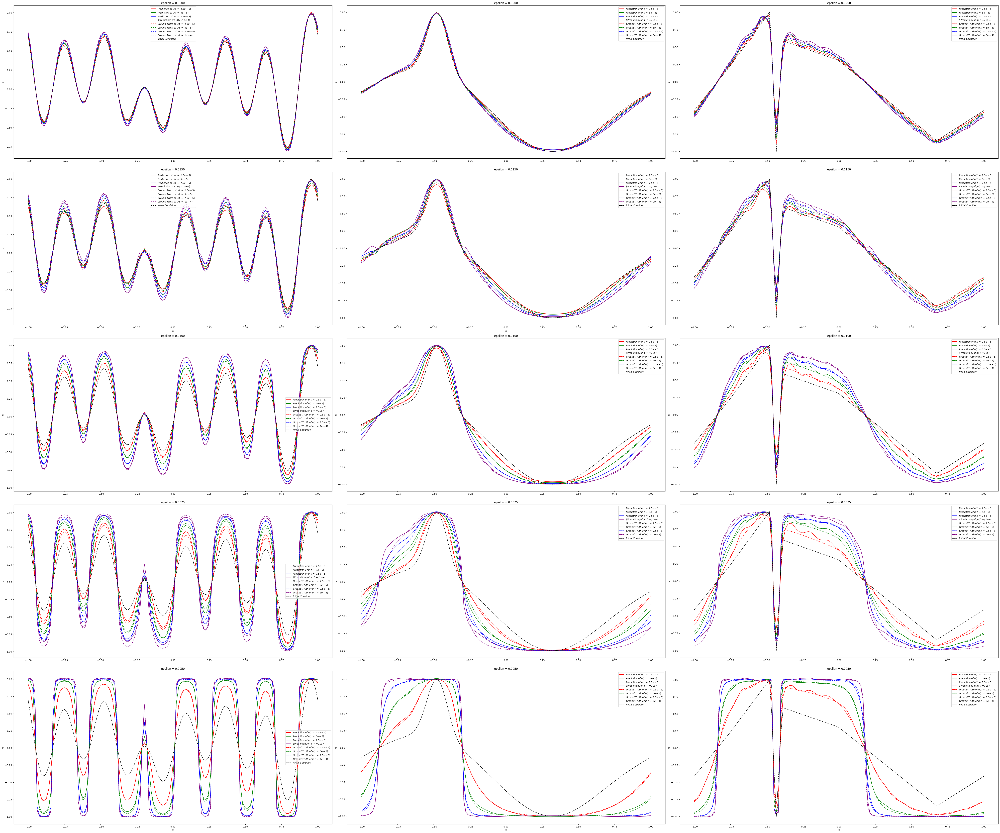

In [39]:
# visualize predictions for different epsilon values and different type of initial conditions
subplot_num = 15
subplot_idx = 0
fig, axs = plt.subplots(5, 3, figsize=(60, 50))

for idx in range(5*3*200):
    if idx % 200 == 0:
        batch = Test_Dataset.__getitem__(idx)
        batch = {k: v.unsqueeze(0).to(device) for k, v in batch.items()}
        pred = model(batch['initial'], batch['epsilon'], batch['times'])
        pred = pred.detach().cpu().numpy()

        grid = np.linspace(-1, 1, 128)

        ax = axs[subplot_idx // 3, subplot_idx % 3]
        # use real line to represent the prediction
        ax.plot(grid, pred[0, 0, :], label = "$Prediction\ of\ u(t\ =\ 2.5e-5)$", color='red')
        ax.plot(grid, pred[0, 1, :], label = "$Prediction\ of\ u(t\ =\ 5e-5)$", color='green')
        ax.plot(grid, pred[0, 2, :], label = "$Prediction\ of\ u(t\ =\ 7.5e-5)$", color='blue')
        ax.plot(grid, pred[0, 3, :], label = "$Prediction\ of\ u(t\ =\ 1e-4)", color='purple')

        # use dot-line to represent the ground truth
        ax.plot(grid, batch['target'][0, 0, :], '--', label = "$Ground\ Truth\ of\ u(t\ =\ 2.5e-5)$", color='red')
        ax.plot(grid, batch['target'][0, 1, :], '--', label = "$Ground\ Truth\ of\ u(t\ =\ 5e-5)$", color='green')
        ax.plot(grid, batch['target'][0, 2, :], '--', label = "$Ground\ Truth\ of\ u(t\ =\ 7.5e-5)$", color='blue')
        ax.plot(grid, batch['target'][0, 3, :], '--', label = "$Ground\ Truth\ of\ u(t\ =\ 1e-4)$", color='purple')
        ax.plot(grid, batch['initial'][0, :], '--', label = "$Initial\ Condition$", color='black')

        ax.set_xlabel("x")
        ax.set_ylabel("u")
        # use 3 digits to represent epsilon
        ax.set_title(f"epsilon = {batch['epsilon'].item():.4f}")
        ax.legend()
        subplot_idx += 1

plt.tight_layout()
plt.show()


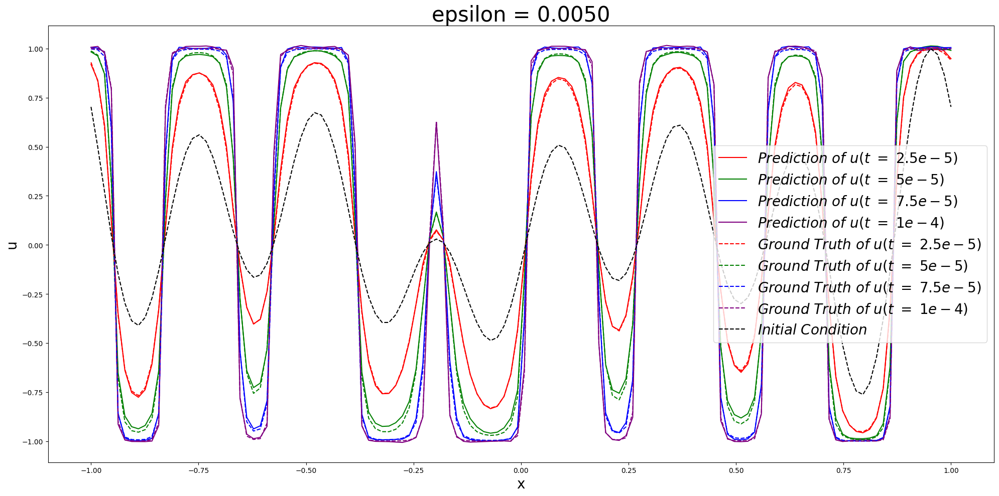

In [40]:
idx = 2400
batch = Test_Dataset.__getitem__(idx)
batch = {k: v.unsqueeze(0).to(device) for k, v in batch.items()}
pred = model(batch['initial'], batch['epsilon'], batch['times'])
pred = pred.detach().cpu().numpy()

grid = np.linspace(-1, 1, 128)

plt.figure(figsize=(20, 10))
# use real line to represent the prediction
plt.plot(grid, pred[0, 0, :], label = "$Prediction\ of\ u(t\ =\ 2.5e-5)$", color='red')
plt.plot(grid, pred[0, 1, :], label = "$Prediction\ of\ u(t\ =\ 5e-5)$", color='green')
plt.plot(grid, pred[0, 2, :], label = "$Prediction\ of\ u(t\ =\ 7.5e-5)$", color='blue')
plt.plot(grid, pred[0, 3, :], label = "$Prediction\ of\ u(t\ =\ 1e-4)$", color='purple')

# use dot-line to represent the ground truth
plt.plot(grid, batch['target'][0, 0, :], '--', label = "$Ground\ Truth\ of\ u(t\ =\ 2.5e-5)$", color='red')
plt.plot(grid, batch['target'][0, 1, :], '--', label = "$Ground\ Truth\ of\ u(t\ =\ 5e-5)$", color='green')
plt.plot(grid, batch['target'][0, 2, :], '--', label = "$Ground\ Truth\ of\ u(t\ =\ 7.5e-5)$", color='blue')
plt.plot(grid, batch['target'][0, 3, :], '--', label = "$Ground\ Truth\ of\ u(t\ =\ 1e-4)$", color='purple')
plt.plot(grid, batch['initial'][0, :], '--', label = "$Initial\ Condition$", color='black')

# adjust the font size of x and y labels
plt.xlabel("x", fontsize=20)
plt.ylabel("u", fontsize=20)
# use 3 digits to represent epsilon and adjust the font size
plt.title(f"epsilon = {batch['epsilon'].item():.4f}", fontsize=30)
# adjust the legend font size
plt.legend(fontsize=20)

plt.tight_layout()
plt.show()


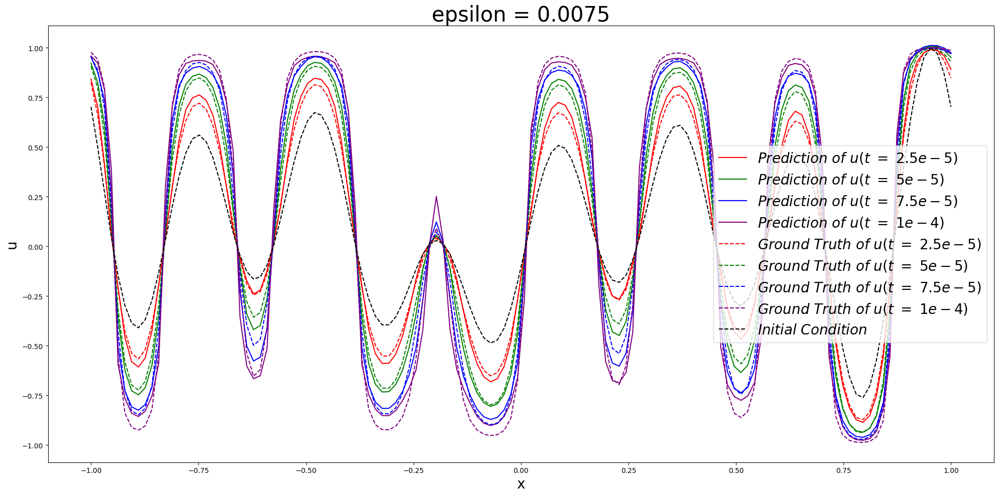

In [41]:
idx = 1800
batch = Test_Dataset.__getitem__(idx)
batch = {k: v.unsqueeze(0).to(device) for k, v in batch.items()}
pred = model(batch['initial'], batch['epsilon'], batch['times'])
pred = pred.detach().cpu().numpy()

grid = np.linspace(-1, 1, 128)

plt.figure(figsize=(20, 10))
# use real line to represent the prediction
plt.plot(grid, pred[0, 0, :], label = "$Prediction\ of\ u(t\ =\ 2.5e-5)$", color='red')
plt.plot(grid, pred[0, 1, :], label = "$Prediction\ of\ u(t\ =\ 5e-5)$", color='green')
plt.plot(grid, pred[0, 2, :], label = "$Prediction\ of\ u(t\ =\ 7.5e-5)$", color='blue')
plt.plot(grid, pred[0, 3, :], label = "$Prediction\ of\ u(t\ =\ 1e-4)$", color='purple')

# use dot-line to represent the ground truth
plt.plot(grid, batch['target'][0, 0, :], '--', label = "$Ground\ Truth\ of\ u(t\ =\ 2.5e-5)$", color='red')
plt.plot(grid, batch['target'][0, 1, :], '--', label = "$Ground\ Truth\ of\ u(t\ =\ 5e-5)$", color='green')
plt.plot(grid, batch['target'][0, 2, :], '--', label = "$Ground\ Truth\ of\ u(t\ =\ 7.5e-5)$", color='blue')
plt.plot(grid, batch['target'][0, 3, :], '--', label = "$Ground\ Truth\ of\ u(t\ =\ 1e-4)$", color='purple')
plt.plot(grid, batch['initial'][0, :], '--', label = "$Initial\ Condition$", color='black')

# adjust the font size of x and y labels
plt.xlabel("x", fontsize=20)
plt.ylabel("u", fontsize=20)
# use 3 digits to represent epsilon and adjust the font size
plt.title(f"epsilon = {batch['epsilon'].item():.4f}", fontsize=30)
# adjust the legend font size
plt.legend(fontsize=20)

plt.tight_layout()
plt.show()

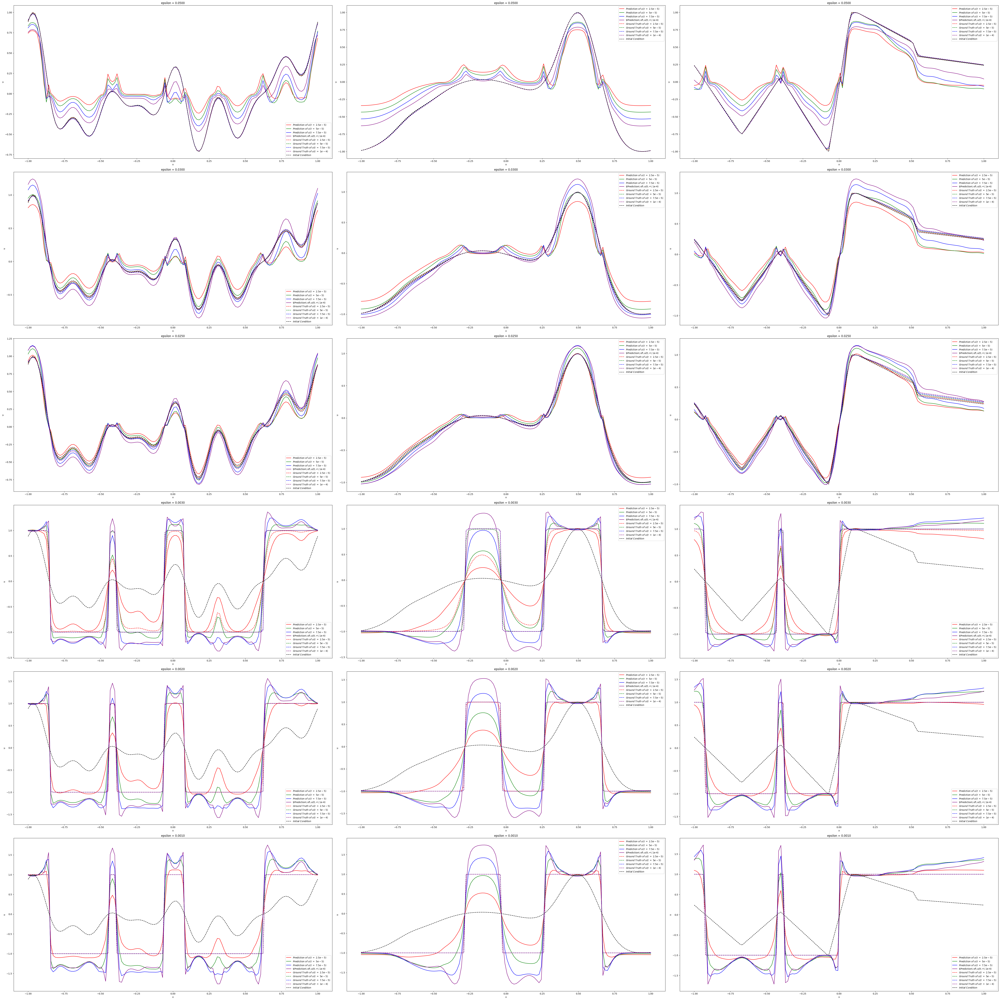

In [42]:
# visualize predictions for different epsilon values and different type of initial conditions
subplot_num = 18
subplot_idx = 0
fig, axs = plt.subplots(6, 3, figsize=(60, 60))

for idx in range(subplot_num*200):
    if idx % 200 == 0:
        batch = OOD_Dataset.__getitem__(idx)
        batch = {k: v.unsqueeze(0).to(device) for k, v in batch.items()}
        pred = model(batch['initial'], batch['epsilon'], batch['times'])
        pred = pred.detach().cpu().numpy()

        grid = np.linspace(-1, 1, 128)

        ax = axs[subplot_idx // 3, subplot_idx % 3]
        # use real line to represent the prediction
        ax.plot(grid, pred[0, 0, :], label = "$Prediction\ of\ u(t\ =\ 2.5e-5)$", color='red')
        ax.plot(grid, pred[0, 1, :], label = "$Prediction\ of\ u(t\ =\ 5e-5)$", color='green')
        ax.plot(grid, pred[0, 2, :], label = "$Prediction\ of\ u(t\ =\ 7.5e-5)$", color='blue')
        ax.plot(grid, pred[0, 3, :], label = "$Prediction\ of\ u(t\ =\ 1e-4)", color='purple')

        # use dot-line to represent the ground truth
        ax.plot(grid, batch['target'][0, 0, :], '--', label = "$Ground\ Truth\ of\ u(t\ =\ 2.5e-5)$", color='red')
        ax.plot(grid, batch['target'][0, 1, :], '--', label = "$Ground\ Truth\ of\ u(t\ =\ 5e-5)$", color='green')
        ax.plot(grid, batch['target'][0, 2, :], '--', label = "$Ground\ Truth\ of\ u(t\ =\ 7.5e-5)$", color='blue')
        ax.plot(grid, batch['target'][0, 3, :], '--', label = "$Ground\ Truth\ of\ u(t\ =\ 1e-4)$", color='purple')
        ax.plot(grid, batch['initial'][0, :], '--', label = "$Initial\ Condition$", color='black')

        ax.set_xlabel("x")
        ax.set_ylabel("u")
        # use 3 digits to represent epsilon
        ax.set_title(f"epsilon = {batch['epsilon'].item():.4f}")
        ax.legend()
        subplot_idx += 1

plt.tight_layout()
plt.show()

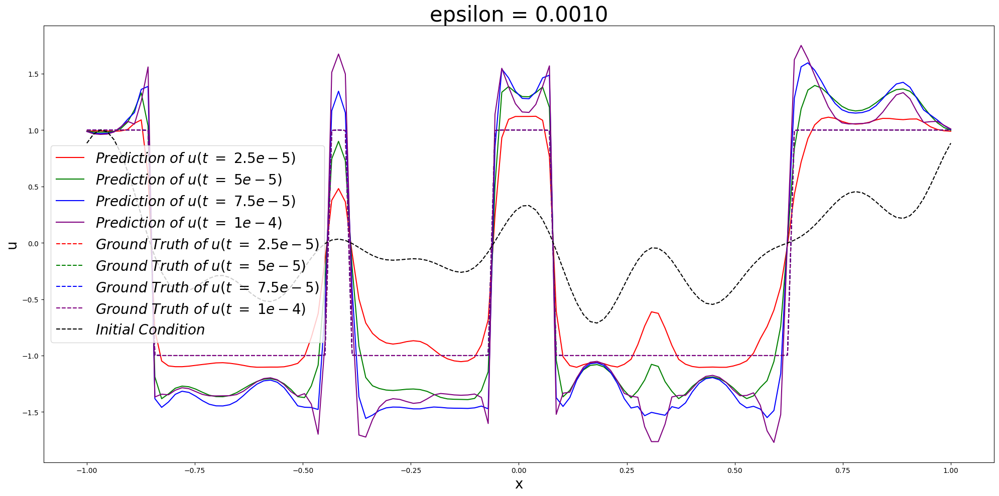

In [43]:
idx = 3000
batch = OOD_Dataset.__getitem__(idx)
batch = {k: v.unsqueeze(0).to(device) for k, v in batch.items()}
pred = model(batch['initial'], batch['epsilon'], batch['times'])
pred = pred.detach().cpu().numpy()

grid = np.linspace(-1, 1, 128)

plt.figure(figsize=(20, 10))
# use real line to represent the prediction
plt.plot(grid, pred[0, 0, :], label = "$Prediction\ of\ u(t\ =\ 2.5e-5)$", color='red')
plt.plot(grid, pred[0, 1, :], label = "$Prediction\ of\ u(t\ =\ 5e-5)$", color='green')
plt.plot(grid, pred[0, 2, :], label = "$Prediction\ of\ u(t\ =\ 7.5e-5)$", color='blue')
plt.plot(grid, pred[0, 3, :], label = "$Prediction\ of\ u(t\ =\ 1e-4)$", color='purple')

# use dot-line to represent the ground truth
plt.plot(grid, batch['target'][0, 0, :], '--', label = "$Ground\ Truth\ of\ u(t\ =\ 2.5e-5)$", color='red')
plt.plot(grid, batch['target'][0, 1, :], '--', label = "$Ground\ Truth\ of\ u(t\ =\ 5e-5)$", color='green')
plt.plot(grid, batch['target'][0, 2, :], '--', label = "$Ground\ Truth\ of\ u(t\ =\ 7.5e-5)$", color='blue')
plt.plot(grid, batch['target'][0, 3, :], '--', label = "$Ground\ Truth\ of\ u(t\ =\ 1e-4)$", color='purple')
plt.plot(grid, batch['initial'][0, :], '--', label = "$Initial\ Condition$", color='black')

# adjust the font size of x and y labels
plt.xlabel("x", fontsize=20)
plt.ylabel("u", fontsize=20)
# use 3 digits to represent epsilon and adjust the font size
plt.title(f"epsilon = {batch['epsilon'].item():.4f}", fontsize=30)
# adjust the legend font size
plt.legend(fontsize=20)

plt.tight_layout()
plt.show()

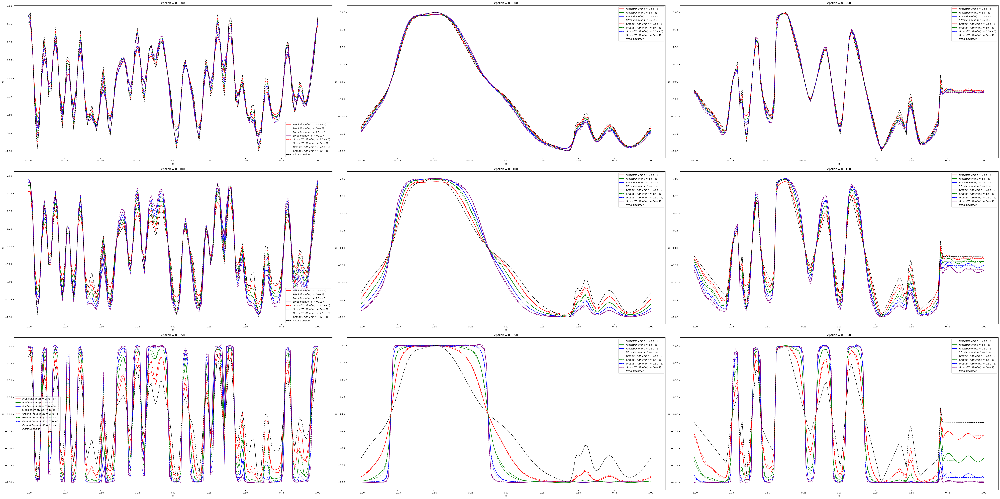

In [44]:
# visualize predictions for different epsilon values and different type of initial conditions
subplot_num = 9
subplot_idx = 0
fig, axs = plt.subplots(3, 3, figsize=(60, 30))

for idx in range(subplot_num*200):
    if idx % 200 == 0:
        batch = High_Freq_Dataset.__getitem__(idx)
        batch = {k: v.unsqueeze(0).to(device) for k, v in batch.items()}
        pred = model(batch['initial'], batch['epsilon'], batch['times'])
        pred = pred.detach().cpu().numpy()

        grid = np.linspace(-1, 1, 128)

        ax = axs[subplot_idx // 3, subplot_idx % 3]
        # use real line to represent the prediction
        ax.plot(grid, pred[0, 0, :], label = "$Prediction\ of\ u(t\ =\ 2.5e-5)$", color='red')
        ax.plot(grid, pred[0, 1, :], label = "$Prediction\ of\ u(t\ =\ 5e-5)$", color='green')
        ax.plot(grid, pred[0, 2, :], label = "$Prediction\ of\ u(t\ =\ 7.5e-5)$", color='blue')
        ax.plot(grid, pred[0, 3, :], label = "$Prediction\ of\ u(t\ =\ 1e-4)", color='purple')

        # use dot-line to represent the ground truth
        ax.plot(grid, batch['target'][0, 0, :], '--', label = "$Ground\ Truth\ of\ u(t\ =\ 2.5e-5)$", color='red')
        ax.plot(grid, batch['target'][0, 1, :], '--', label = "$Ground\ Truth\ of\ u(t\ =\ 5e-5)$", color='green')
        ax.plot(grid, batch['target'][0, 2, :], '--', label = "$Ground\ Truth\ of\ u(t\ =\ 7.5e-5)$", color='blue')
        ax.plot(grid, batch['target'][0, 3, :], '--', label = "$Ground\ Truth\ of\ u(t\ =\ 1e-4)$", color='purple')
        ax.plot(grid, batch['initial'][0, :], '--', label = "$Initial\ Condition$", color='black')

        ax.set_xlabel("x")
        ax.set_ylabel("u")
        # use 3 digits to represent epsilon
        ax.set_title(f"epsilon = {batch['epsilon'].item():.4f}")
        ax.legend()
        subplot_idx += 1

plt.tight_layout()
plt.show()

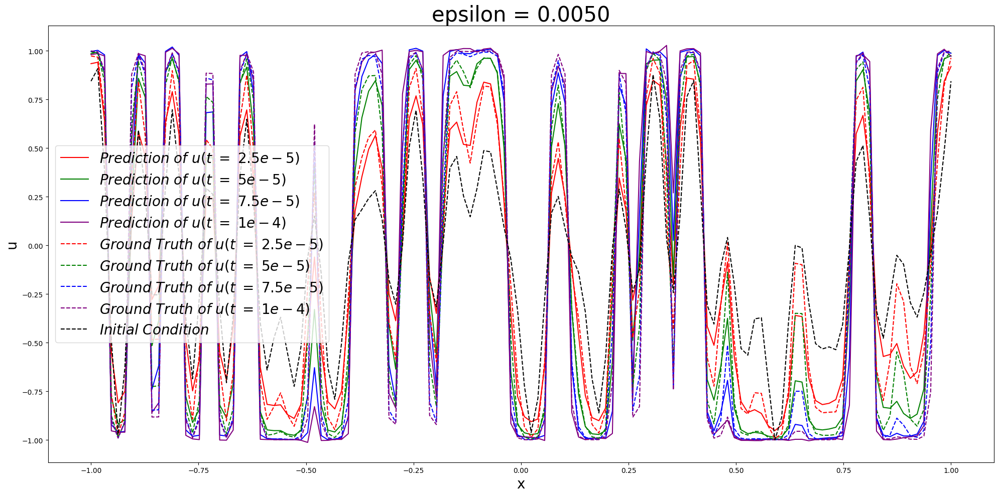

In [45]:
idx = 1200
batch = High_Freq_Dataset.__getitem__(idx)
batch = {k: v.unsqueeze(0).to(device) for k, v in batch.items()}
pred = model(batch['initial'], batch['epsilon'], batch['times'])
pred = pred.detach().cpu().numpy()

grid = np.linspace(-1, 1, 128)

plt.figure(figsize=(20, 10))
# use real line to represent the prediction
plt.plot(grid, pred[0, 0, :], label = "$Prediction\ of\ u(t\ =\ 2.5e-5)$", color='red')
plt.plot(grid, pred[0, 1, :], label = "$Prediction\ of\ u(t\ =\ 5e-5)$", color='green')
plt.plot(grid, pred[0, 2, :], label = "$Prediction\ of\ u(t\ =\ 7.5e-5)$", color='blue')
plt.plot(grid, pred[0, 3, :], label = "$Prediction\ of\ u(t\ =\ 1e-4)$", color='purple')

# use dot-line to represent the ground truth
plt.plot(grid, batch['target'][0, 0, :], '--', label = "$Ground\ Truth\ of\ u(t\ =\ 2.5e-5)$", color='red')
plt.plot(grid, batch['target'][0, 1, :], '--', label = "$Ground\ Truth\ of\ u(t\ =\ 5e-5)$", color='green')
plt.plot(grid, batch['target'][0, 2, :], '--', label = "$Ground\ Truth\ of\ u(t\ =\ 7.5e-5)$", color='blue')
plt.plot(grid, batch['target'][0, 3, :], '--', label = "$Ground\ Truth\ of\ u(t\ =\ 1e-4)$", color='purple')
plt.plot(grid, batch['initial'][0, :], '--', label = "$Initial\ Condition$", color='black')

# adjust the font size of x and y labels
plt.xlabel("x", fontsize=20)
plt.ylabel("u", fontsize=20)
# use 3 digits to represent epsilon and adjust the font size
plt.title(f"epsilon = {batch['epsilon'].item():.4f}", fontsize=30)
# adjust the legend font size
plt.legend(fontsize=20)

plt.tight_layout()
plt.show()